In [1]:
### ABOUT THIS NOTEBOOK!

# this notebook is used to analyze and visualization of several points in DBSCAN cluster analysis
# 1. DBSCAN modelling
# 2. Finding best epsilon value for DBSCAN
# 3. Evaluate DBSCAN modelling with silhouette score

# REQUIREMENT!
# please install those library first before running the code.

# pip install numpy
# pip install geopandas
# pip install pandas
# pip install matplotlib
# pip install scikit-learn

# 01 Import the following library.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [72]:
# 02 Import cofee shop point of interest (poi) data.
coffee_shop = gpd.read_file("../data/coffee_shop.gpkg")
coffee_shop.crs

<Projected CRS: EPSG:32748>
Name: WGS 84 / UTM zone 48S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 102°E and 108°E, southern hemisphere between 80°S and equator, onshore and offshore. Indonesia.
- bounds: (102.0, -80.0, 108.0, 0.0)
Coordinate Operation:
- name: UTM zone 48S
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [73]:
# 03 Transforming data to zip.
coords = np.array(list(zip(coffee_shop.geometry.x, coffee_shop.geometry.y)))

if coffee_shop.crs and coffee_shop.crs.is_geographic:
    coffee_shop_proj = coffee_shop.to_crs(epsg=32748)  
    coords = np.array(
        list(zip(coffee_shop_proj.geometry.x, coffee_shop_proj.geometry.y))
    )
    print(f"CRS converted to EPSG:32748 (meter). Unit epsilon = meter.")
else:
    print(f"CRS already projected: {coffee_shop.crs}")

print(f"Total point: {len(coords)}")

CRS already projected: EPSG:32748
Total point: 429


k (MinPts) : 4
Elbow index : 49
Optimal Epsilon Number : 804.56 meter


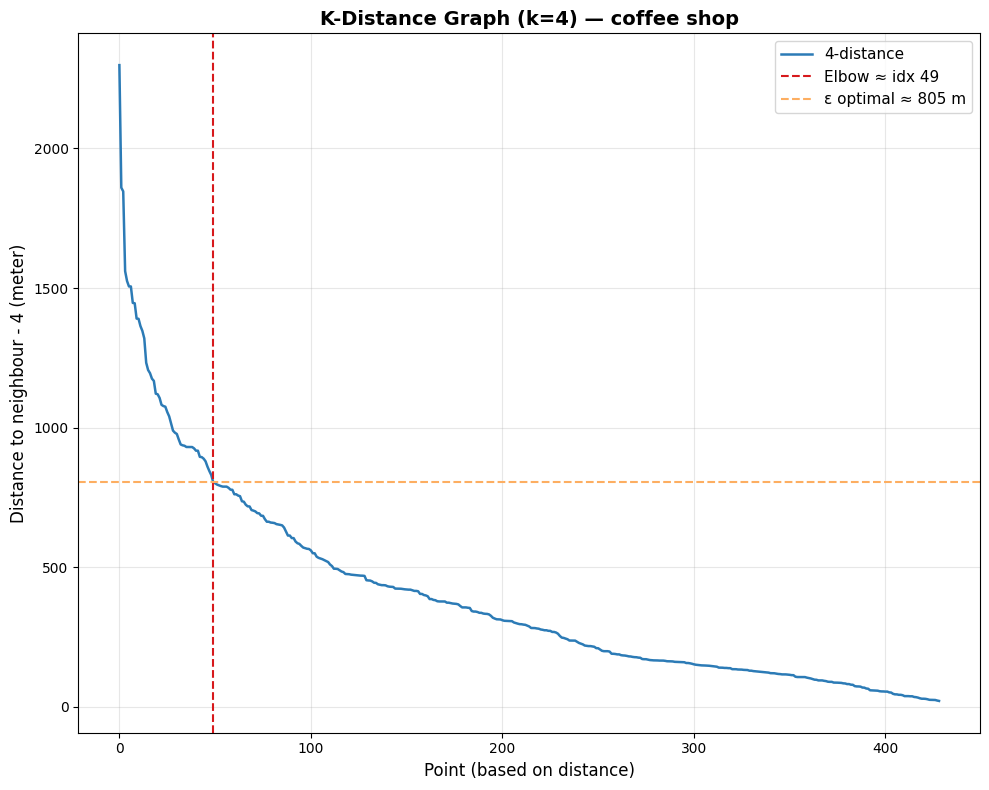

In [74]:
# 04 Finding best epsilon from k-distance graph method
K = 4 
# K = 4 is choosed based on the dimension K = 2 x dimension (geographical is x and y, so 2 x 2 is 4)

nbrs = NearestNeighbors(n_neighbors=K).fit(coords)
distances, _ = nbrs.kneighbors(coords)

k_distances = np.sort(distances[:, K - 1])[::-1]

x = np.arange(len(k_distances))
y = k_distances
p1 = np.array([x[0], y[0]])
p2 = np.array([x[-1], y[-1]])
line_vec = p2 - p1
line_vec_norm = line_vec / np.linalg.norm(line_vec)

vec_from_first = np.column_stack([x - p1[0], y - p1[1]])
scalar_proj = vec_from_first @ line_vec_norm
proj = np.outer(scalar_proj, line_vec_norm)
rejection = vec_from_first - proj
distances_to_line = np.linalg.norm(rejection, axis=1)

elbow_idx = np.argmax(distances_to_line)
optimal_eps = k_distances[elbow_idx]

print(f"k (MinPts) : {K}")
print(f"Elbow index : {elbow_idx}")
print(f"Optimal Epsilon Number : {optimal_eps:.2f} meter")

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(k_distances, color="#2c7bb6", linewidth=1.8, label=f"{K}-distance")
ax.axvline(x=elbow_idx, color="#d7191c", linestyle="--", linewidth=1.5, label=f"Elbow ≈ idx {elbow_idx}")
ax.axhline(y=optimal_eps, color="#fdae61", linestyle="--", linewidth=1.5, label=f"ε optimal ≈ {optimal_eps:.0f} m")
ax.set_xlabel("Point (based on distance)", fontsize=12)
ax.set_ylabel(f"Distance to neighbour - {K} (meter)", fontsize=12)
ax.set_title(f"K-Distance Graph (k={K}) — coffee shop", fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [75]:
# 05 DBSCAN initial modelling.
EPS = optimal_eps     
MIN_SAMPLES = K       

print(f"epsilon : {EPS:.2f} m")
print(f"min_samples :  {MIN_SAMPLES}")

db = DBSCAN(eps=optimal_eps, min_samples=MIN_SAMPLES, metric="euclidean")
labels = db.fit_predict(coords)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"cluster count : {n_clusters}")
print(f"noise count (outlier) : {n_noise} point ({n_noise/len(labels)*100:.1f} %)")

coffee_shop["dbscan_cluster"] = labels

epsilon : 804.56 m
min_samples :  4
cluster count : 8
noise count (outlier) : 31 point (7.2 %)


In [76]:
# 05 DBSCAN Initial evaluation and visualization with silhouette score.
mask_valid = labels != -1
n_valid = np.sum(mask_valid)
n_unique_valid = len(set(labels[mask_valid]))

if n_unique_valid >= 2 and n_valid >= 2:
    sil_score = silhouette_score(coords[mask_valid], labels[mask_valid])
    print(f"from {n_valid} point (non-noise), {n_unique_valid} cluster")
    print(f"silhouette score: {sil_score:.4f}")
    print(f"model interpretation : {'good (> 0.5)' if sil_score > 0.5 else 'decent (0.25–0.5)' if sil_score > 0.25 else 'weak (< 0.25)'}")
else:
    sil_score = None
    print(f"[!] silhouette cannot be proceed")
    print(f"valid cluster: {n_unique_valid}, non-noise point: {n_valid}")

from 398 point (non-noise), 8 cluster
silhouette score: 0.1436
model interpretation : weak (< 0.25)



---  (K = 4) ---
 eps_m  n_cluster  n_noise  pct_noise  silhouette  davies_bouldin  largest_cluster_pct  cluster_size_std
    50          7      397      92.54      0.9554          0.0585                18.75              0.79
   100         17      338      78.79      0.8847          0.1436                 8.79              1.32
   200         28      230      53.61      0.7205          0.3025                 9.05              3.37
   300         24      187      43.59      0.5983          0.3462                25.62             13.05
   400         29      123      28.67      0.5403          0.4376                20.59             12.25
   500         21       87      20.28      0.4555          0.4219                44.15             31.72
   600         21       65      15.15      0.2475          0.4990                57.42             44.02
   700         15       45      10.49      0.2622          0.7126                61.46             58.65
   805          8       31       7.23

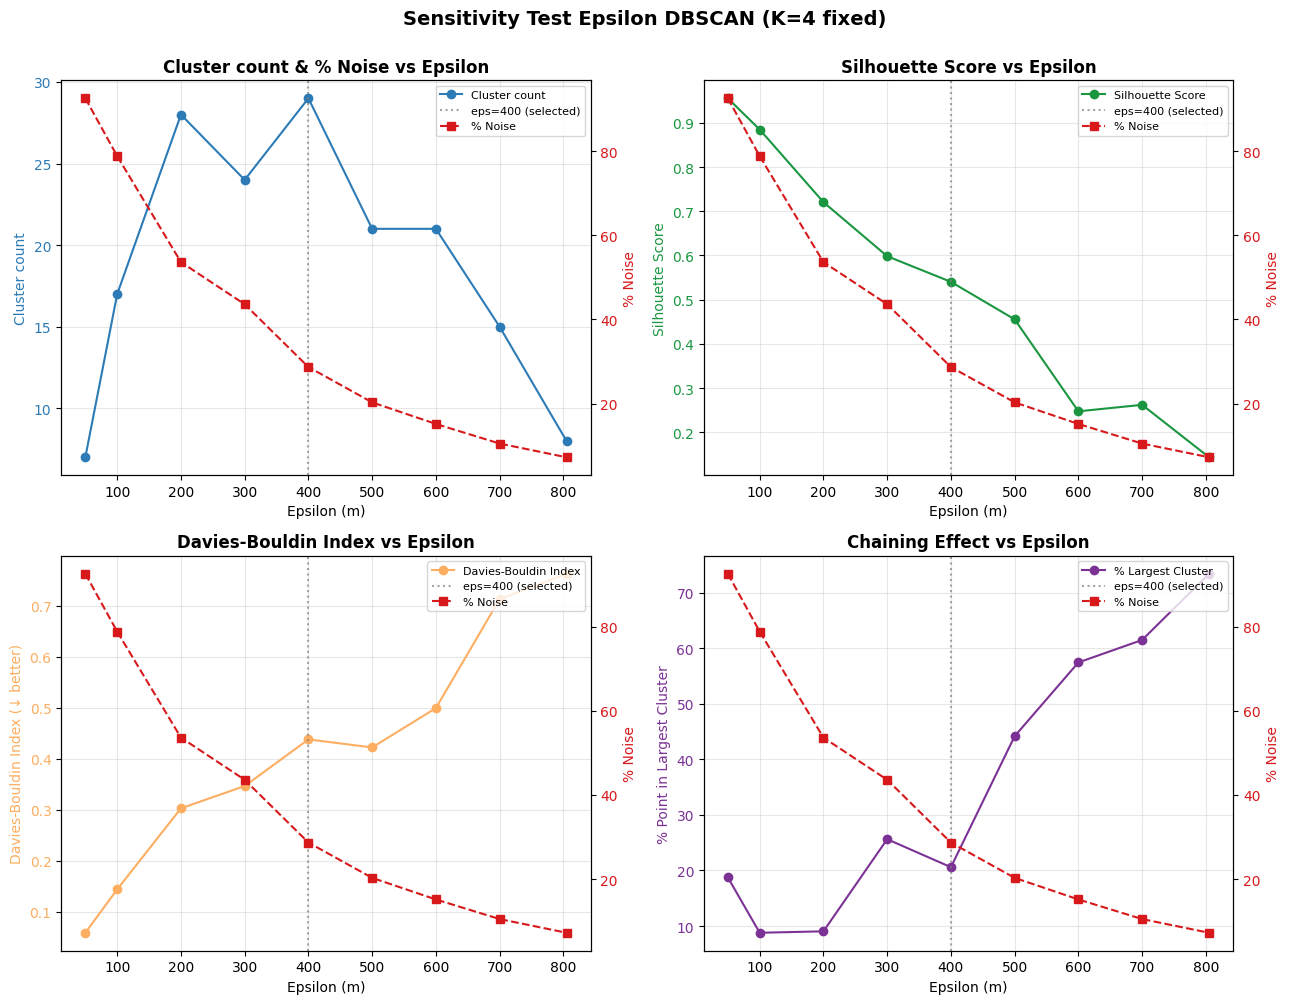

In [83]:
# 06 DBSCAN epsilon value tuning with sensitivity test
# based on "weak interpretation" in recent model, we need to tune the epsilon value
eps_list = [50, 100, 200, 300, 400, 500, 600, 700, 805]

sensitivity_results = []

for eps_test in eps_list:
    db_test = DBSCAN(eps=eps_test, min_samples=K, metric="euclidean")
    labels_test = db_test.fit_predict(coords)

    n_cluster_test = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise_test   = np.sum(labels_test == -1)
    pct_noise_test = n_noise_test / len(labels_test) * 100

    mask_valid_test = labels_test != -1
    n_valid_test = np.sum(mask_valid_test)
    n_unique_valid_test = len(set(labels_test[mask_valid_test]))

    if n_unique_valid_test >= 2 and n_valid_test >= 2:
        sil_test = silhouette_score(coords[mask_valid_test], labels_test[mask_valid_test])
        dbi_test = davies_bouldin_score(coords[mask_valid_test], labels_test[mask_valid_test])
    else:
        sil_test = np.nan
        dbi_test = np.nan

    if n_cluster_test > 0:
        cluster_sizes = pd.Series(labels_test[mask_valid_test]).value_counts()
        largest_cluster_pct = cluster_sizes.max() / n_valid_test * 100
        cluster_size_std = cluster_sizes.std()
    else:
        largest_cluster_pct = np.nan
        cluster_size_std = np.nan

    sensitivity_results.append({
        "eps_m": eps_test,
        "n_cluster": n_cluster_test,
        "n_noise": n_noise_test,
        "pct_noise": round(pct_noise_test, 2),
        "silhouette": round(sil_test, 4) if not np.isnan(sil_test) else np.nan,
        "davies_bouldin": round(dbi_test, 4) if not np.isnan(dbi_test) else np.nan,
        "largest_cluster_pct": round(largest_cluster_pct, 2) if not np.isnan(largest_cluster_pct) else np.nan,
        "cluster_size_std": round(cluster_size_std, 2) if not np.isnan(cluster_size_std) else np.nan,
    })

df_sensitivity = pd.DataFrame(sensitivity_results)

print(f"\n---  (K = {K}) ---")
print(df_sensitivity.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

def _combined_legend(ax_main, ax_twin, loc="upper right", fontsize=8):
    h1, l1 = ax_main.get_legend_handles_labels()
    h2, l2 = ax_twin.get_legend_handles_labels()
    ax_main.legend(h1 + h2, l1 + l2, loc=loc, fontsize=fontsize)

NOISE_COLOR = "#d7191c"

ax1 = axes[0, 0]
ax1.plot(df_sensitivity["eps_m"], df_sensitivity["n_cluster"], "o-", color="#2c7bb6", label="Cluster count")
ax1.set_xlabel("Epsilon (m)")
ax1.set_ylabel("Cluster count", color="#2c7bb6")
ax1.tick_params(axis="y", labelcolor="#2c7bb6")
ax1b = ax1.twinx()
ax1b.plot(df_sensitivity["eps_m"], df_sensitivity["pct_noise"], "s--", color=NOISE_COLOR, label="% Noise")
ax1b.set_ylabel("% Noise", color=NOISE_COLOR)
ax1b.tick_params(axis="y", labelcolor=NOISE_COLOR)
ax1.axvline(x=400, color="grey", linestyle=":", alpha=0.7, label="eps=400 (selected)")
ax1.set_title("Cluster count & % Noise vs Epsilon", fontweight="bold")
_combined_legend(ax1, ax1b)
ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
ax2.plot(df_sensitivity["eps_m"], df_sensitivity["silhouette"], "o-", color="#1a9641", label="Silhouette Score")
ax2.axvline(x=400, color="grey", linestyle=":", alpha=0.7, label="eps=400 (selected)")
ax2.set_xlabel("Epsilon (m)")
ax2.set_ylabel("Silhouette Score", color="#1a9641")
ax2.tick_params(axis="y", labelcolor="#1a9641")
ax2b = ax2.twinx()
ax2b.plot(df_sensitivity["eps_m"], df_sensitivity["pct_noise"], "s--", color=NOISE_COLOR, label="% Noise")
ax2b.set_ylabel("% Noise", color=NOISE_COLOR)
ax2b.tick_params(axis="y", labelcolor=NOISE_COLOR)
ax2.set_title("Silhouette Score vs Epsilon", fontweight="bold")
_combined_legend(ax2, ax2b, fontsize=8)
ax2.grid(True, alpha=0.3)

ax3 = axes[1, 0]
ax3.plot(df_sensitivity["eps_m"], df_sensitivity["davies_bouldin"], "o-", color="#fdae61", label="Davies-Bouldin Index")
ax3.set_xlabel("Epsilon (m)")
ax3.set_ylabel("Davies-Bouldin Index (↓ better)", color="#fdae61")
ax3.tick_params(axis="y", labelcolor="#fdae61")
ax3b = ax3.twinx()
ax3b.plot(df_sensitivity["eps_m"], df_sensitivity["pct_noise"], "s--", color=NOISE_COLOR, label="% Noise")
ax3b.set_ylabel("% Noise", color=NOISE_COLOR)
ax3b.tick_params(axis="y", labelcolor=NOISE_COLOR)
ax3.axvline(x=400, color="grey", linestyle=":", alpha=0.7, label="eps=400 (selected)")
ax3.set_title("Davies-Bouldin Index vs Epsilon", fontweight="bold")
_combined_legend(ax3, ax3b)
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.plot(df_sensitivity["eps_m"], df_sensitivity["largest_cluster_pct"], "o-", color="#7b3294", label="% Largest Cluster")
ax4.set_xlabel("Epsilon (m)")
ax4.set_ylabel("% Point in Largest Cluster", color="#7b3294")
ax4.tick_params(axis="y", labelcolor="#7b3294")
ax4b = ax4.twinx()
ax4b.plot(df_sensitivity["eps_m"], df_sensitivity["pct_noise"], "s--", color=NOISE_COLOR, label="% Noise")
ax4b.set_ylabel("% Noise", color=NOISE_COLOR)
ax4b.tick_params(axis="y", labelcolor=NOISE_COLOR)
ax4.axvline(x=400, color="grey", linestyle=":", alpha=0.7, label="eps=400 (selected)")
ax4.set_title("Chaining Effect vs Epsilon", fontweight="bold")
_combined_legend(ax4, ax4b)
ax4.grid(True, alpha=0.3)

plt.suptitle(f"Sensitivity Test Epsilon DBSCAN (K={K} fixed)", fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
plt.show()


epsilon : 400.00 m
min_samples :  4
cluster count : 29
noise count (outlier) : 123 point (28.7 %)


C:\Users\Ahmad Haikal\AppData\Local\Temp\ipykernel_34980\2252395282.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", max(n_clusters, 1))


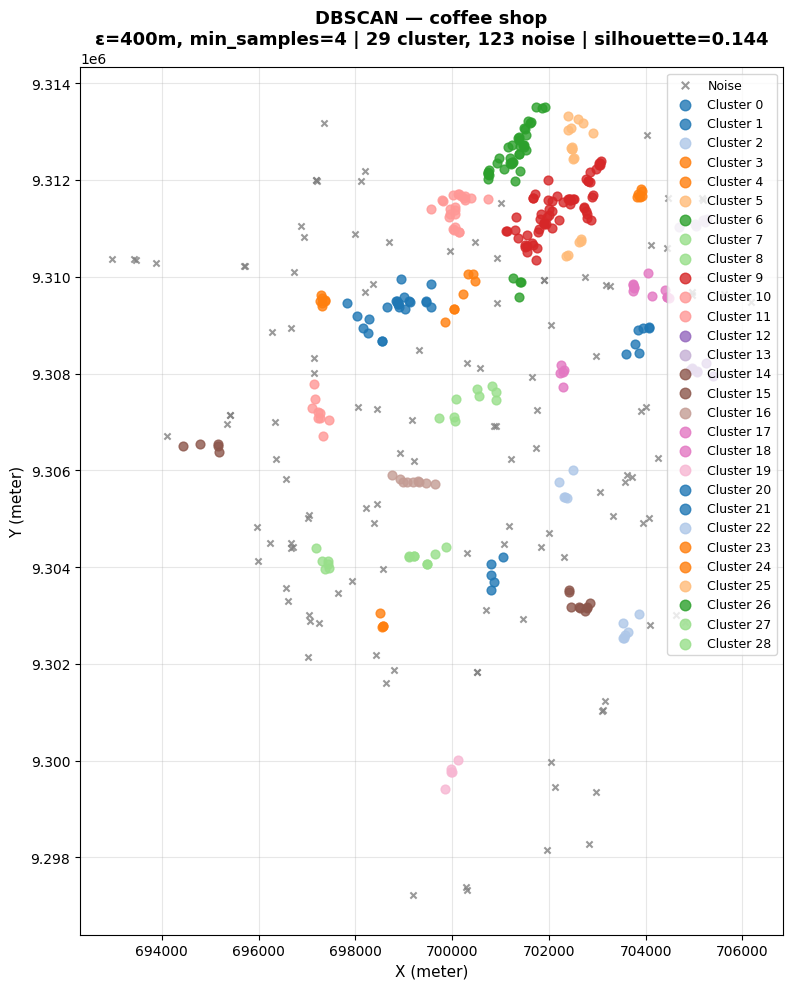

In [82]:
# 07 DBSCAN refined modelling and final visualization.
EPS = 400    
MIN_SAMPLES = K       

print(f"epsilon : {EPS:.2f} m")
print(f"min_samples :  {MIN_SAMPLES}")

db = DBSCAN(eps=400, min_samples=MIN_SAMPLES, metric="euclidean")
labels = db.fit_predict(coords)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"cluster count : {n_clusters}")
print(f"noise count (outlier) : {n_noise} point ({n_noise/len(labels)*100:.1f} %)")

coffee_shop["dbscan_cluster"] = labels

fig, ax = plt.subplots(figsize=(12, 10))

unique_labels = sorted(set(labels))
cmap = plt.cm.get_cmap("tab20", max(n_clusters, 1))

for label in unique_labels:
    mask = labels == label
    if label == -1:
        color, marker, zorder, size = "grey", "x", 2, 20
        cluster_name = "Noise"
    else:
        color  = cmap(label % 20)
        marker = "o"
        zorder = 3
        size   = 40
        cluster_name = f"Cluster {label}"

    ax.scatter(
        coords[mask, 0], coords[mask, 1],
        c=[color], marker=marker, s=size,
        label=cluster_name, zorder=zorder, alpha=0.8
    )

title_str = f"DBSCAN — coffee shop\nε={400}m, min_samples={MIN_SAMPLES} | {n_clusters} cluster, {n_noise} noise"
if sil_score is not None : title_str += f" | silhouette={sil_score:.3f}"

ax.set_title(title_str, fontsize=13, fontweight="bold")
ax.set_xlabel("X (meter)", fontsize=11)
ax.set_ylabel("Y (meter)", fontsize=11)
ax.legend(loc="upper right", fontsize=9, markerscale=1.2)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
# 08 DBSCAN summary table.
print("\n--- Summary per Cluster ---")
print(f"{'Cluster':>10} | {'Point Count':>14}")
print("-" * 28)
for lbl in sorted(set(labels)):
    nama = "Noise" if lbl == -1 else f"Cluster {lbl}"
    print(f"{nama:>10} | {np.sum(labels == lbl):>14}")


--- Summary per Cluster ---
   Cluster |    Point Count
----------------------------
     Noise |            123
 Cluster 0 |              7
 Cluster 1 |             17
 Cluster 2 |              6
 Cluster 3 |              7
 Cluster 4 |              7
 Cluster 5 |             12
 Cluster 6 |             38
 Cluster 7 |              8
 Cluster 8 |              5
 Cluster 9 |             63
Cluster 10 |              9
Cluster 11 |             23
Cluster 12 |              7
Cluster 13 |              6
Cluster 14 |              5
Cluster 15 |              9
Cluster 16 |              9
Cluster 17 |             11
Cluster 18 |              5
Cluster 19 |              5
Cluster 20 |              5
Cluster 21 |              7
Cluster 22 |              5
Cluster 23 |              4
Cluster 24 |              7
Cluster 25 |              5
Cluster 26 |              4
Cluster 27 |              4
Cluster 28 |              6
